In [1]:
import pandas as pd

PIMA_url = 'https://raw.githubusercontent.com/PinkWink/ML_tutorial' +\
          '/master/dataset/diabetes.csv'
PIMA = pd.read_csv(PIMA_url, index_col=0)
PIMA.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,,,,,,,,
6,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
8,183,64,0,0,23.3,0.672,32,1
1,89,66,23,94,28.1,0.167,21,0
0,137,40,35,168,43.1,2.288,33,1


In [2]:
PIMA.info()

<class 'pandas.DataFrame'>
Index: 768 entries, 6 to 1
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 54.0 KB


In [3]:
PIMA = PIMA.astype('float')
PIMA.info()

<class 'pandas.DataFrame'>
Index: 768 entries, 6 to 1
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    float64
 1   BloodPressure             768 non-null    float64
 2   SkinThickness             768 non-null    float64
 3   Insulin                   768 non-null    float64
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    float64
 7   Outcome                   768 non-null    float64
dtypes: float64(8)
memory usage: 54.0 KB


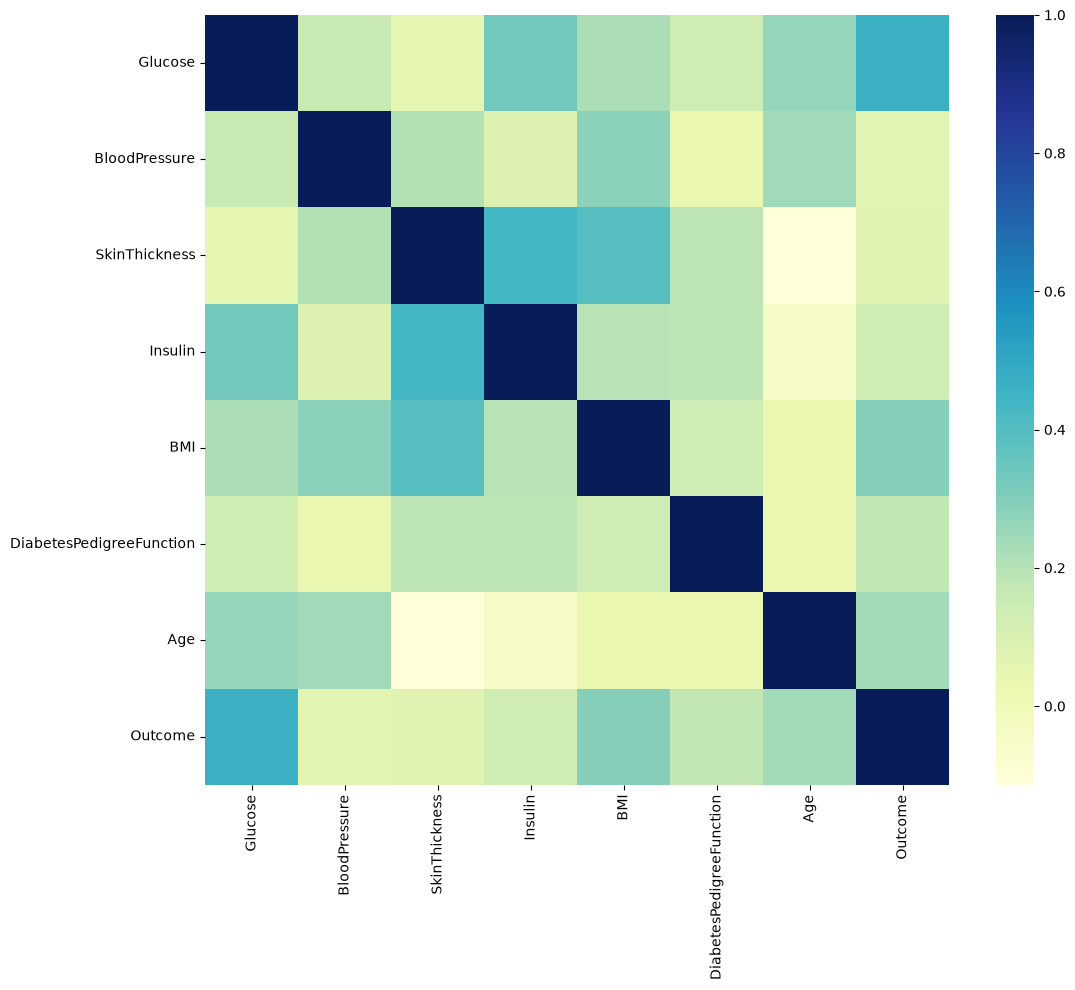

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))
sns.heatmap(PIMA.corr(), cmap='YlGnBu')
plt.show()

In [ ]:
(PIMA == 0).astype(int).sum() # 값이 0인 데이터 개수

Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [ ]:
zero_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'BMI']
PIMA[zero_features] = PIMA[zero_features].replace(0, PIMA[zero_features].mean()) # 결측치를 평균값으로 대체
(PIMA == 0).astype(int).sum()

Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                     374
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [8]:
from sklearn.model_selection import train_test_split

X = PIMA.drop(['Outcome'], axis=1)
y = PIMA['Outcome']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=13, stratify=y # stratify: Outcome을 같은 비율로 분배
)

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

estimators = [
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='liblinear', random_state=13)),
]

pipe_lr = Pipeline(estimators)
pipe_lr.fit(X_train, y_train)
pred = pipe_lr.predict(X_test)

In [10]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    roc_auc_score,
    f1_score,
)

print("Accuracy : ", accuracy_score(y_test, pred))
print("Recall : ", recall_score(y_test, pred))
print("Precision : ", precision_score(y_test, pred))
print("AUC score : ", roc_auc_score(y_test, pred))
print("F1 Score : ", f1_score(y_test, pred))

Accuracy :  0.7727272727272727
Recall :  0.6296296296296297
Precision :  0.6938775510204082
AUC score :  0.7398148148148149
F1 Score :  0.6601941747572816


In [12]:
coeff = list(pipe_lr['clf'].coef_[0])
labels = list(X_train.columns)
coeff

[np.float64(1.1856414196649465),
 np.float64(-0.14991603648402754),
 np.float64(0.03280316142119013),
 np.float64(-0.17236816858500859),
 np.float64(0.6000817793544071),
 np.float64(0.34694880167432757),
 np.float64(0.3459451906952143)]

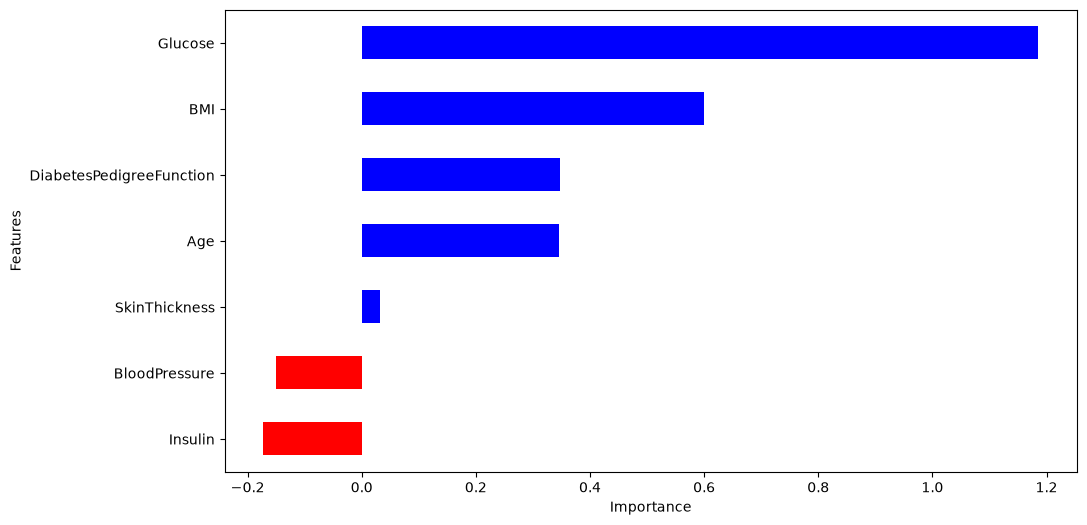

In [13]:
features = pd.DataFrame({'Features': labels, 'importance': coeff})
features.sort_values(by=['importance'], ascending=True, inplace=True)
features['positive'] = features['importance'] > 0
features.set_index('Features', inplace=True)
features['importance'].plot(
    kind='barh',
    figsize=(11, 6),
    color=features['positive'].map({True: 'blue', False: 'red'}),
)
plt.xlabel('Importance')
plt.show()